In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Exercício 1

Utilizando o método ingênuo gere uma amostra de tamanho $M=1000$ de uma variável geométrica com parâmetro $p$. Compara o gráfico da sua distribuição com a função do numpy. Além disso, compare o que acontece quando você varia o valor $p$

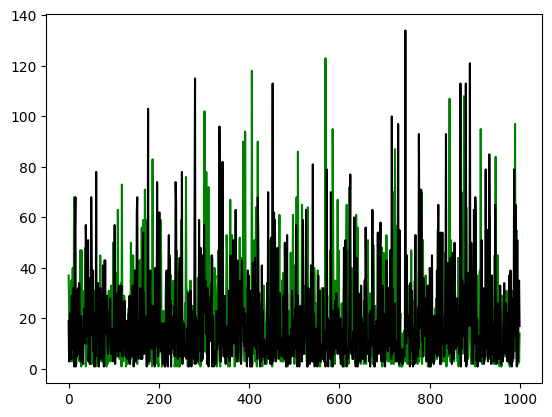

In [ ]:
amostra = []
N = 1000
for i in range(N):
  uniform = np.random.uniform(0,1,1)
  p = 0.05
  bernoulli = []
  for numero in uniform:
    if numero >= p:
      numero = 0
    else:
      numero = 1
    bernoulli.append(numero)

  X = 1
  B = bernoulli
  while B[0] == 0:
    X += 1
    uniform = np.random.uniform(0,1,1)
    for numero in uniform:
      if numero >= p:
        numero = 0
      else:
        numero = 1
      B[0] = numero
  amostra.append(X)

amostra2 = np.random.geometric(0.05, 1000)
plt.plot(amostra2, color='Green')
plt.plot(amostra, color= 'Black')


# Exercício 2

Repita o exercício anterior, porém utilizando o método de inversão. Compare o tempo gasto por esse método versus o método ingênuo do item anterior usando a função `time.time` variando o $p$, ou seja, no eixo $y$ coloque o tempo e no eixo $x$ coloque $p$.

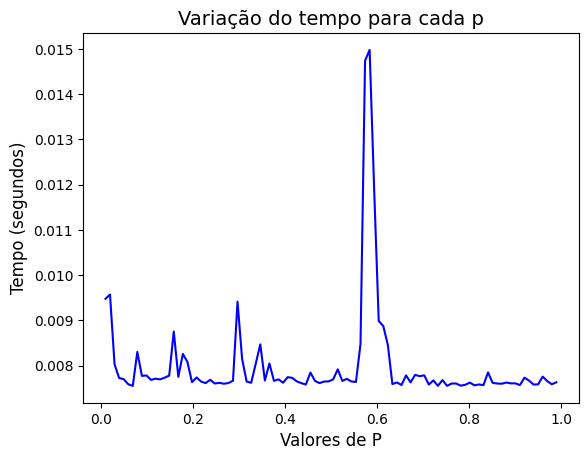

In [ ]:
amostra3 = []
tempos_p = []
vals_p = np.linspace(0.01, 0.99, 100)
for p in vals_p:
  N = 1000
  inicio = time.time()
  for i in range(N):
    u = np.random.uniform()
    num = np.log(1-u)
    den = np.log(1-p)
    x = np.ceil(num/den)
    amostra3.append(x)
  fim = time.time()
  tempo = fim-inicio
  tempos_p.append(tempo)

plt.plot(vals_p, tempos_p, color="blue")

plt.xlabel("Valores de P", fontsize=12)
plt.ylabel("Tempo (segundos)", fontsize=12)
plt.title("Variação do tempo para cada p", fontsize=14)

plt.show()

# Exercício 3

Gere uma amostra de tamanho $M=1000$ de uma Poisson com parâmetro $\lambda$ usando o método recursivo.  

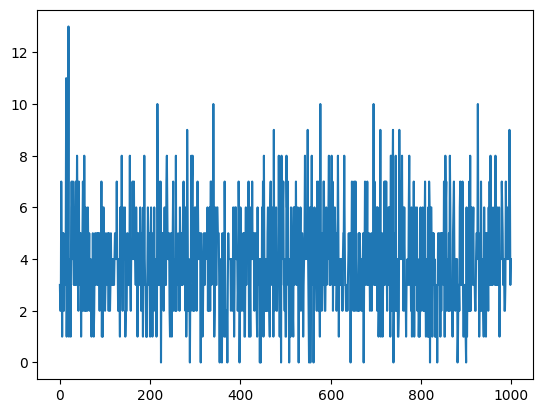

In [ ]:
amostra_poisson = []
N = 1000
for i in range(N):
  lam = 4
  U = np.random.uniform(0, 1, 1)
  i = 0
  p = np.exp(-lam)
  F = p
  while U > F:
    i += 1
    p = (lam/i)*p
    F += p
  amostra_poisson.append(i)
